# Morphological Image Processing

In [1]:
import inspect

import imageio
import numpy as np
from matplotlib import pyplot as plt
from skimage import morphology
from scipy import ndimage

import morphological_processing_sol

def diff_check(img1, img2, tol=1):
    img1 = img1.astype(bool)
    img2 = img2.astype(bool)

    num_diff = np.sum(img1 != img2)

    if num_diff > tol:
        return False
    else:
        return True


## Erosion and dilation

Write a function `morpho_erode(I, B, padval)` that returns the morphological erosion of a binary image `I` by a structuring element `B`. 



In [4]:
def morpho_erode(I, B):
    """
    Perform morphological erosion on a binary image.

    Parameters
    ----------
    image : numpy.ndarray
        The input binary image as a 2D NumPy array.
    structure : numpy.ndarray, optional
        The structuring element used for erosion. If None, a cross-shaped structuring element is used (default is None).
    iterations : int, optional
        The number of times erosion is applied (default is 1).

    Returns
    -------
    numpy.ndarray
        The eroded binary image as a 2D NumPy array.
    """

    # YOUR CODE HERE
    #get dimensions of image and structuring element
    M,N = I.shape
    p,q = B.shape
    B_sum = np.sum(B)
    # initialize output image
    im_out = np.zeros_like(I)
    # pad image, start with zero padding
    im_pad = np.pad(I,((p//2,p//2),(q//2,q//2)))
    # iterate through image
    for i in range(M):
        for j in range(N):
            #find the neighborhood of interest
            hood = im_pad[i:i+p, j:j+q]
            # determine output pixel
            # mask the area of interest with the structure, then compare their sums
            mask = np.sum(hood*B)
            if mask == B_sum:
                im_out[i,j] = 1
            # redundant code, we initialized im_out to all 0s
            # else:
            #     im_out[i,j] = 0
    return im_out

###########################
# TESTING
I = np.ones((5,5))
B = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
])

result = morpho_erode(I, B)
print(result)

[[0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 0.]
 [0. 1. 1. 1. 0.]
 [0. 1. 1. 1. 0.]
 [0. 0. 0. 0. 0.]]


In [3]:
im = np.zeros((100, 150))

# create random blocks in image
for _ in range(10):
    idx_lx = np.random.randint(0, 100)
    idx_hx = np.random.randint(idx_lx, 100)

    idx_ly = np.random.randint(0, 150)
    idx_hy = np.random.randint(idx_ly, 150)

    im[idx_ly:idx_hy, idx_lx:idx_hx] = 1

# erode the image
se = np.zeros((3, 3))
se[0, :] = 1
se[:, 1] = 1

im_eroded = morpho_erode(im, se)
im_eroded_sol = ndimage.binary_erosion(im, se)


assert diff_check(im_eroded_sol, im_eroded, 3)

source = inspect.getsource(morpho_erode)
assert "ndimage" not in source

Write a function `morpho_dilate(I, B, padval)` that returns the morphological dilation.  This uses the same parameters of the previous function.


In [7]:
def morpho_dilate(I, B):
    """
    Perform morphological dilation on a binary image.

    Parameters
    ----------
    image : numpy.ndarray
        The input binary image as a 2D NumPy array.
    structure : numpy.ndarray, optional
        The structuring element used for dilation. If None, a cross-shaped structuring element is used (default is None).
    iterations : int, optional
        The number of times dilation is applied (default is 1).

    Returns
    -------
    numpy.ndarray
        The dilated binary image as a 2D NumPy array.
    """

    # YOUR CODE HERE
    M,N = I.shape
    p,q = B.shape
    # initialize output image
    im_out = np.zeros_like(I)
    # pad image
    im_pad = np.pad(I,((p//2,p//2),(q//2,q//2)))
    #iterate through image
    for i in range(M):
        for j in range(N):
            # get area of interest
            hood = im_pad[i:i+p, j:j+q]
            # determine output pixel
            if np.sum(hood*B) > 0:
                im_out[i,j] = 1
    return im_out


#####################
# TESTING
I = np.zeros((5,5))
I[2,2] = 1

B = np.ones((3,3))

print(I,"\n")
print(morpho_dilate(I, B))

[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]] 

[[0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 0.]
 [0. 1. 1. 1. 0.]
 [0. 1. 1. 1. 0.]
 [0. 0. 0. 0. 0.]]


In [8]:
from scipy import ndimage

im = np.zeros((100, 150))

# create random blocks in image
for _ in range(10):
    idx_lx = np.random.randint(0, 100)
    idx_hx = np.random.randint(idx_lx, 100)

    idx_ly = np.random.randint(0, 150)
    idx_hy = np.random.randint(idx_ly, 150)

    im[idx_ly:idx_hy, idx_lx:idx_hx] = 1

# erode the image
se = np.zeros((3, 3))
se[1, :] = 1
se[:, 1] = 1

im_dilated = morpho_dilate(im, se)
im_dilated_sol = ndimage.binary_dilation(im, se)

assert diff_check(im_dilated_sol, im_dilated, 3)


source = inspect.getsource(morpho_dilate)
assert "ndimage" not in source

Read in `UTK_inv.tif`.  Using a $3\times 3$ structuring element of 1's, erode this image successively three times and display the result.  Save this result as `im_erode`.  Using the same SE as before, dilate the image with the same SE and three times.  Save this result as `im_dilate`.

You might need to change the image data type to `bool`. 

In [11]:
# YOUR CODE HERE
im_orig = imageio.v2.imread("UTK_inv.tif")
B = np.array([
    [1,1,1],
    [1,1,1],
    [1,1,1]
])
im_erode = morpho_erode(im_orig,B)
im_erode = morpho_erode(im_erode,B)
im_erode = morpho_erode(im_erode,B)

im_dilate = morpho_dilate(im_orig,B)
im_dilate = morpho_dilate(im_dilate,B)
im_dilate = morpho_dilate(im_dilate,B)


Text(0.5, 1.0, 'Dilated')

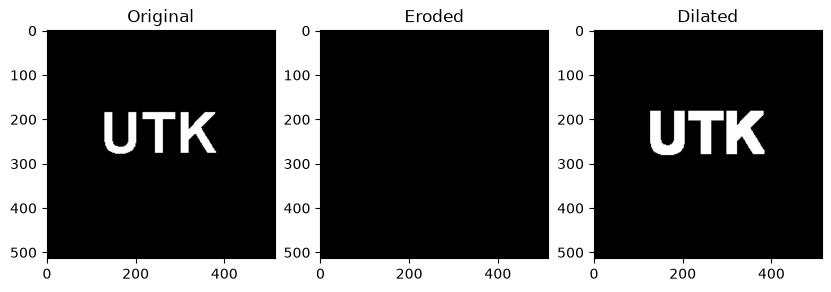

In [12]:
assert isinstance(im_erode, np.ndarray)
assert isinstance(im_dilate, np.ndarray)

plt.figure(figsize=(10, 10))
plt.subplot(131)
plt.imshow(im_orig, cmap="gray")
plt.title("Original")

plt.subplot(132)
plt.imshow(im_erode, cmap="gray")
plt.title("Eroded")

plt.subplot(133)
plt.imshow(im_dilate, cmap="gray")
plt.title("Dilated")


## Opening and closing

Write a function `morpho_open(I, B)` for performing and returning morphological opening of binary image `I` by structural element `B`.  



In [13]:
def morpho_open(I, B):
    """
    Perform morphological opening on a binary image.

    Parameters
    ----------
    I : numpy.ndarray
        The input binary image as a 2D NumPy array.
    B : numpy.ndarray
        The structuring element used for opening.

    Returns
    -------
    numpy.ndarray
        The opened binary image as a 2D NumPy array.
    """
    # YOUR CODE HERE
    # Erode image by B
    # Dialte image by B
    return morpho_dilate(morpho_erode(I,B),B)

In [14]:
im = np.zeros((100, 150))

# create random blocks in image
for _ in range(10):
    idx_lx = np.random.randint(0, 100)
    idx_hx = np.random.randint(idx_lx, 100)

    idx_ly = np.random.randint(0, 150)
    idx_hy = np.random.randint(idx_ly, 150)

    im[idx_ly:idx_hy, idx_lx:idx_hx] = 1

# erode the image
se = np.zeros((3, 3))
se[1, :] = 1
se[:, 1] = 1

im_open = morpho_open(im, se)
im_open_sol = ndimage.binary_opening(im, se)

assert diff_check(im_open, im_open_sol, 3)

source = inspect.getsource(morpho_open)
assert "ndimage" not in source

Write a function `morpho_close(I, B)` for performing and returning the closing of binary image `I` by structuring element `B`.

In [15]:
def morpho_close(I, B):
    """
    Perform morphological closing on a binary image.

    Parameters
    ----------
    I : numpy.ndarray
        The input binary image as a 2D NumPy array.
    B : numpy.ndarray
        The structuring element used for closing.

    Returns
    -------
    numpy.ndarray
        The closed binary image as a 2D NumPy array.
    """
    # YOUR CODE HERE
    return morpho_erode(morpho_dilate(I,B),B)

In [16]:
im = np.zeros((100, 150))

# create random blocks in image
for _ in range(10):
    idx_lx = np.random.randint(0, 100)
    idx_hx = np.random.randint(idx_lx, 100)

    idx_ly = np.random.randint(0, 150)
    idx_hy = np.random.randint(idx_ly, 150)

    im[idx_ly:idx_hy, idx_lx:idx_hx] = 1

# erode the image
se = np.zeros((3, 3))
se[1, :] = 1
se[:, 1] = 1

im_close = morpho_close(im, se)
im_close_sol = ndimage.binary_closing(im, se)

assert diff_check(im_close, im_close_sol, 3)

source = inspect.getsource(morpho_close)
assert "ndimage" not in source

Read the image `circuitmask.tif`.  Use opening to eliminate connections between the center and the border pads.  Save this image as `im_open`.  Use the smallest SE (which is a $n\times n$ block of 1's) that will eliminate all connections except for the four largest.  

In [29]:
# YOUR CODE HERE
im_orig = imageio.v2.imread('circuitmask.tif')
n = 5
B = np.ones((n,n))
im_open = morpho_open(im_orig,B)

Text(0.5, 1.0, 'Opened')

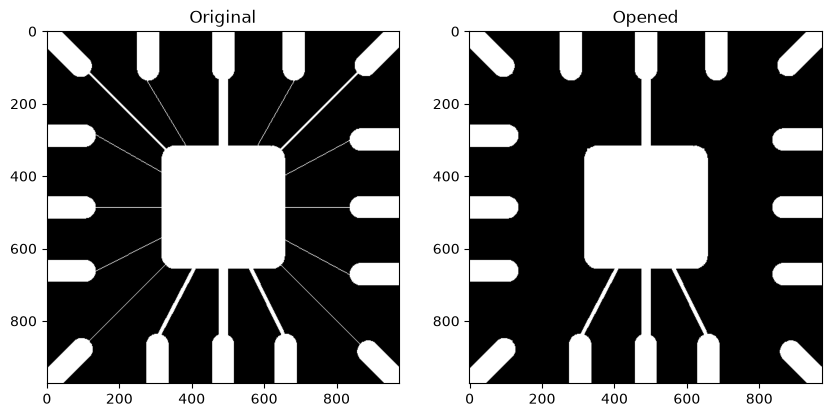

In [30]:
assert isinstance(im_open, np.ndarray)

plt.figure(figsize=(10, 10))
plt.subplot(121)
plt.imshow(im_orig, cmap="gray")
plt.title("Original")

plt.subplot(122)
plt.imshow(im_open, cmap="gray")
plt.title("Opened")


## Boundary extraction

Write a function `morpho_boundary(I, B)` that uses \verb+B+ to extract and return the boundary of objects of the foreground pixels in the binary image `I`.  

In [35]:
def morpho_boundary(I, B):
    """
    Compute the morphological boundary of a binary image.

    Parameters
    ----------
    I : numpy.ndarray
        The input binary image as a 2D NumPy array.
    B : numpy.ndarray
        The structuring element used for boundary detection.

    Returns
    -------
    numpy.ndarray
        The boundary of the binary image as a 2D NumPy array.
    """
    # YOUR CODE HERE
    I = I.astype(int)
    return I - morpho_erode(I,B)

In [36]:
from scipy import ndimage

im = np.zeros((100, 150))

# create random blocks in image
for _ in range(10):
    idx_lx = np.random.randint(0, 100)
    idx_hx = np.random.randint(idx_lx, 100)

    idx_ly = np.random.randint(0, 150)
    idx_hy = np.random.randint(idx_ly, 150)

    im[idx_ly:idx_hy, idx_lx:idx_hx] = 1

# erode the image
se = np.zeros((3, 3))
se[1, :] = 1
se[:, 1] = 1

im_close = morpho_boundary(im, se)
im_close_sol = morphological_processing_sol.morpho_boundary(im, se)

assert diff_check(im_close, im_close_sol, 3)

source = inspect.getsource(morpho_close)
assert "ndimage" not in source

Read the image `testpattern512-binary.tif` whose objects are black.  Compute the complement of the timage so the objects are composed of 1-value foreground pixels.  Use the function `morpho_boundary()` where `B` is a $3\times 3$ structuring element of 1s to find the boundary.  Please display the boundary.

In [37]:
# YOUR CODE HERE
im = imageio.v2.imread('testpattern512-binary.tif')
im_comp = 255 - im
B = np.ones((3,3))
im_boundary = morpho_boundary(im,B)

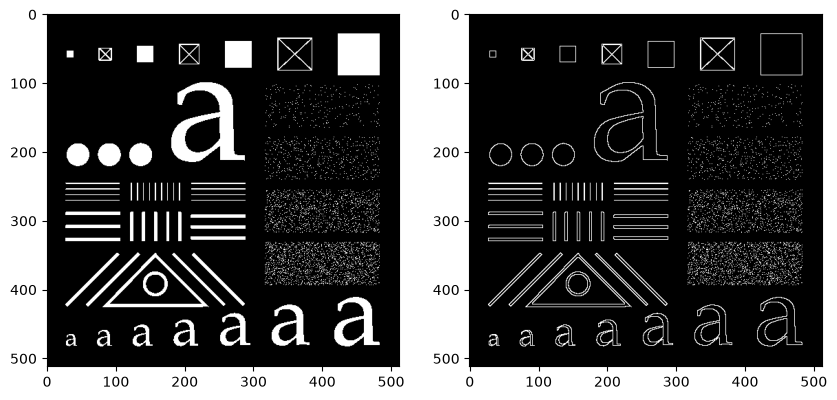

In [38]:
assert isinstance(im_boundary, np.ndarray)

plt.figure(figsize=(10, 10))
plt.subplot(121)
plt.imshow(im, cmap="gray")

plt.subplot(122)
plt.imshow(im_boundary, cmap="gray")

